In [20]:

import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

partidas = 10000
turnos = 100

filas = 5
columnas = 5

inicio_A = (0, 0)
inicio_B = (4, 4)

acciones = [
    "Arriba",
    "Abajo",
    "Izquierda",
    "Derecha",
    "Quedarse"
]

movimientos = {
    "Arriba": (0, -1),
    "Abajo": (0, 1),
    "Izquierda": (-1, 0),
    "Derecha": (1, 0),
    "Quedarse": (0, 0)
}

costo_movimiento = 0
penalizacion_limite = 0.2

frutas = ["manzana", "naranja", "uvas", "sandia"]

valores_frutas = {
    "manzana": 1,
    "naranja": 2,
    "uvas": 3,
    "sandia": 5
}

cantidades = [0, 1, 2, 3, 4]

prob_cantidad = {
    1: [0.05, 0.15, 0.45, 0.25, 0.10],
    2: [0.10, 0.20, 0.30, 0.30, 0.10],
    3: [0.25, 0.35, 0.25, 0.10, 0.05],
    4: [0.15, 0.15, 0.25, 0.25, 0.20],
    5: [0.05, 0.10, 0.20, 0.35, 0.30]
}

prob_frutas = {
    1: [0.65, 0.20, 0.10, 0.05],
    2: [0.20, 0.40, 0.25, 0.15],
    3: [0.40, 0.30, 0.20, 0.10],
    4: [0.25, 0.25, 0.25, 0.25],
    5: [0.10, 0.15, 0.25, 0.50]
}



mapa_perfiles = np.zeros((filas, columnas), dtype=int)

mapa_perfiles[1, 1] = 1
mapa_perfiles[1, 3] = 2
mapa_perfiles[3, 1] = 3
mapa_perfiles[3, 3] = 4
mapa_perfiles[2, 2] = 5


def entorno(x, y):

    perfil = mapa_perfiles[y, x]

    if perfil == 0:
        return 0, []

    cantidad = np.random.choice(
        cantidades,
        p=prob_cantidad[perfil]
    )

    if cantidad == 0:
        return 0, []

    frutas_obtenidas = np.random.choice(
        frutas,
        size=cantidad,
        p=prob_frutas[perfil]
    )

    recompensa = sum(
        valores_frutas[fruta]
        for fruta in frutas_obtenidas
    )

    return recompensa, frutas_obtenidas


def softmax(x):

    exp_x = np.exp(x - np.max(x))

    return exp_x / np.sum(exp_x)


alpha_A = 0.95
epsilon_A = 0.1

alpha_B = 0.1


Q = {}
H = {}


def inicializar_estado(estado):

    if estado not in Q:
        Q[estado] = {
            accion: 0 for accion in acciones
        }

    if estado not in H:
        H[estado] = np.zeros(len(acciones))


print("Mapa de perfiles:")
print(mapa_perfiles)

print("\nEntorno bidimensional configurado correctamente.")


Mapa de perfiles:
[[0 0 0 0 0]
 [0 1 0 2 0]
 [0 0 5 0 0]
 [0 3 0 4 0]
 [0 0 0 0 0]]

Entorno bidimensional configurado correctamente.


In [22]:
def elegir_accion_A(estado):

    inicializar_estado(estado)

    if np.random.uniform(0, 1) < epsilon_A:

        accion = np.random.choice(acciones)

    else:

        maxQ = -float("inf")

        mejores_acciones = []

        for accion_actual in acciones:

            if Q[estado][accion_actual] > maxQ:

                maxQ = Q[estado][accion_actual]
                mejores_acciones = [accion_actual]

            elif Q[estado][accion_actual] == maxQ:

                mejores_acciones.append(accion_actual)

        accion = np.random.choice(mejores_acciones)

    return accion


def elegir_accion_B(estado):

    inicializar_estado(estado)

    pi = softmax(H[estado])

    accion = np.random.choice(
        acciones,
        p=pi
    )

    return accion

def mover_agente(posicion, accion):

    x, y = posicion

    dx, dy = movimientos[accion]

    nuevo_x = x + dx
    nuevo_y = y + dy

    if (
        nuevo_x < 0 or nuevo_x >= columnas
        or nuevo_y < 0 or nuevo_y >= filas
    ):

        return posicion, 0, True

    penalizacion = 0

    if accion != "Quedarse":

        penalizacion = costo_movimiento

    return (nuevo_x, nuevo_y), penalizacion, False


print("Métodos de decisión configurados correctamente.")


Métodos de decisión configurados correctamente.


In [23]:

puntos_medios_A = np.zeros(turnos)
puntos_medios_B = np.zeros(turnos)

recompensas_medias_A = np.zeros(turnos)
recompensas_medias_B = np.zeros(turnos)

puntos_finales_A = []
puntos_finales_B = []

historial = []


for partida in range(partidas):

    posicion_A = inicio_A
    posicion_B = inicio_B

    puntos_A = 0
    puntos_B = 0

    contador_juntos = 0

    recompensas_B = []

    registro_partida = []

    for turno in range(turnos):

        estado = (
            posicion_A[0],
            posicion_A[1],
            posicion_B[0],
            posicion_B[1],
            contador_juntos
        )

        inicializar_estado(estado)

        accion_A = elegir_accion_A(estado)
        accion_B = elegir_accion_B(estado)

        posicion_anterior_A = posicion_A
        posicion_anterior_B = posicion_B

        nueva_posicion_A, penalizacion_A, limite_A = mover_agente(
            posicion_A, accion_A
        )

        nueva_posicion_B, penalizacion_B, limite_B = mover_agente(
            posicion_B, accion_B
        )

        posicion_A = nueva_posicion_A
        posicion_B = nueva_posicion_B

        if posicion_A == posicion_B:

            if (
                posicion_anterior_A == posicion_anterior_B
                and posicion_A == posicion_anterior_A
            ):

                contador_juntos = min(
                    contador_juntos + 1,
                    4
                )

            else:

                contador_juntos = 1

        else:

            contador_juntos = 0

        recompensa_A, frutas_A = entorno(
            posicion_A[0],
            posicion_A[1]
        )

        recompensa_B, frutas_B = entorno(
            posicion_B[0],
            posicion_B[1]
        )

        recompensa_A -= penalizacion_A

        recompensa_B -= penalizacion_B

        if limite_A:
            recompensa_A -= penalizacion_limite

        if limite_B:
            recompensa_B -= penalizacion_limite

        castigo = contador_juntos >= 4

        if castigo:

            recompensa_A *= 0.5
            recompensa_B *= 0.5

        puntos_A += recompensa_A
        puntos_B += recompensa_B

        Q[estado][accion_A] += alpha_A * (
            recompensa_A - Q[estado][accion_A]
        )

        recompensas_B.append(recompensa_B)

        recompensa_media_B = np.mean(recompensas_B)

        pi = softmax(H[estado])

        indice_accion_B = acciones.index(accion_B)

        for j in range(len(acciones)):

            if j == indice_accion_B:

                H[estado][j] += (
                    alpha_B
                    * (recompensa_B - recompensa_media_B)
                    * (1 - pi[j])
                )

            else:

                H[estado][j] -= (
                    alpha_B
                    * (recompensa_B - recompensa_media_B)
                    * pi[j]
                )

        registro = {

            "turno": turno + 1,

            "estado": estado,

            "x_A": posicion_A[0],
            "y_A": posicion_A[1],

            "x_B": posicion_B[0],
            "y_B": posicion_B[1],

            "accion_A": accion_A,
            "accion_B": accion_B,

            "frutas_A": list(frutas_A),
            "frutas_B": list(frutas_B),

            "recompensa_A": recompensa_A,
            "recompensa_B": recompensa_B,

            "puntos_A": puntos_A,
            "puntos_B": puntos_B,

            "contador_juntos": contador_juntos,

            "castigo": castigo,

            "limite_A": limite_A,
            "limite_B": limite_B
        }

        registro_partida.append(registro)

        puntos_medios_A[turno] += puntos_A
        puntos_medios_B[turno] += puntos_B

        recompensas_medias_A[turno] += recompensa_A
        recompensas_medias_B[turno] += recompensa_B

    puntos_finales_A.append(puntos_A)
    puntos_finales_B.append(puntos_B)

    if partida == partidas - 1:

        historial = registro_partida


puntos_medios_A /= partidas
puntos_medios_B /= partidas

recompensas_medias_A /= partidas
recompensas_medias_B /= partidas


print("Entrenamiento finalizado correctamente.")


Entrenamiento finalizado correctamente.


RESULTADOS DEL ENTRENAMIENTO
------------------------------------
Promedio de puntos Agente A: 542.45
Promedio de puntos Agente B: 582.03
Mejor resultado Agente A: 1023.00
Mejor resultado Agente B: 996.00

ULTIMA PARTIDA
------------------------------------
Turno  Posición A   Posición B   Acción A     Acción B     Recomp. A   Recomp. B   Juntos  Castigo 
1      (0, 1)       (4, 4)       Abajo        Quedarse     0.00        0.00        0       False   
2      (1, 1)       (3, 4)       Derecha      Izquierda    1.00        0.00        0       False   
3      (1, 1)       (3, 3)       Quedarse     Arriba       2.00        8.00        0       False   
4      (1, 1)       (3, 3)       Quedarse     Quedarse     1.00        10.00       0       False   
5      (0, 1)       (3, 3)       Izquierda    Quedarse     0.00        9.00        0       False   
6      (1, 1)       (3, 3)       Derecha      Quedarse     2.00        9.00        0       False   
7      (1, 1)       (3, 3)       Quedarse 

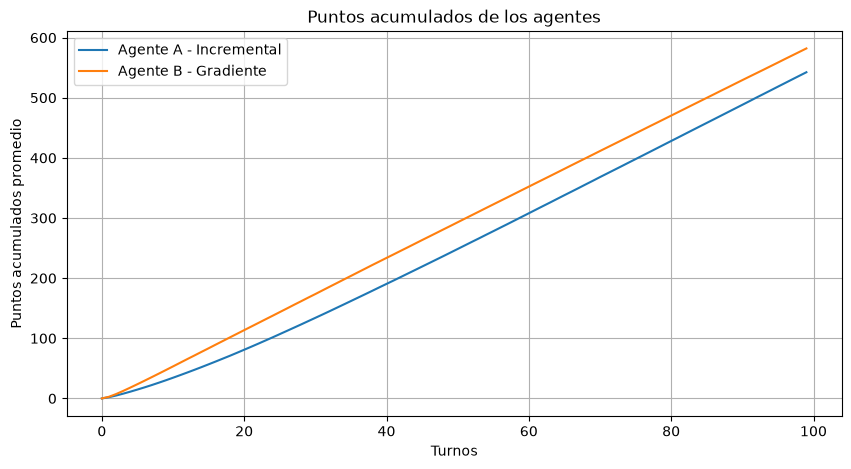

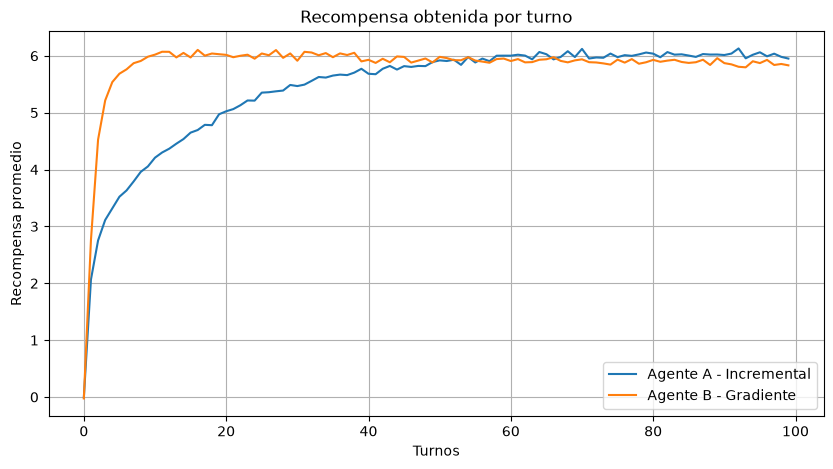

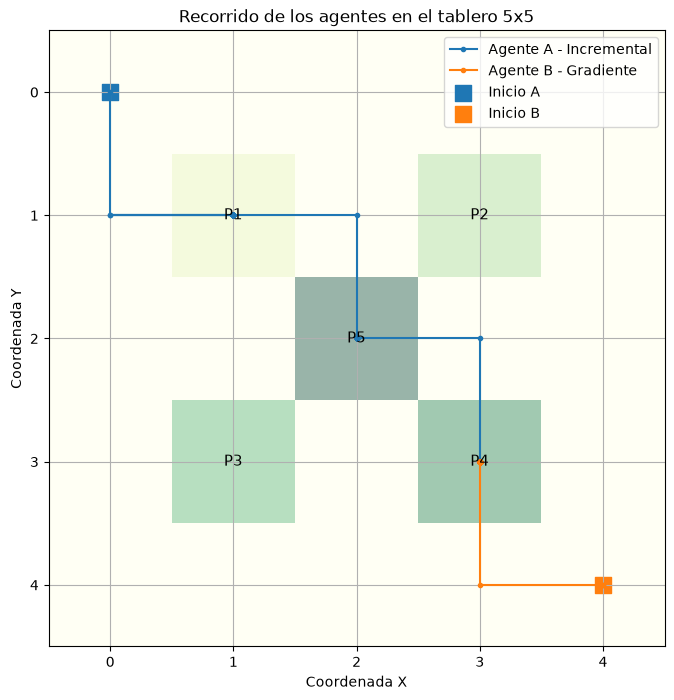

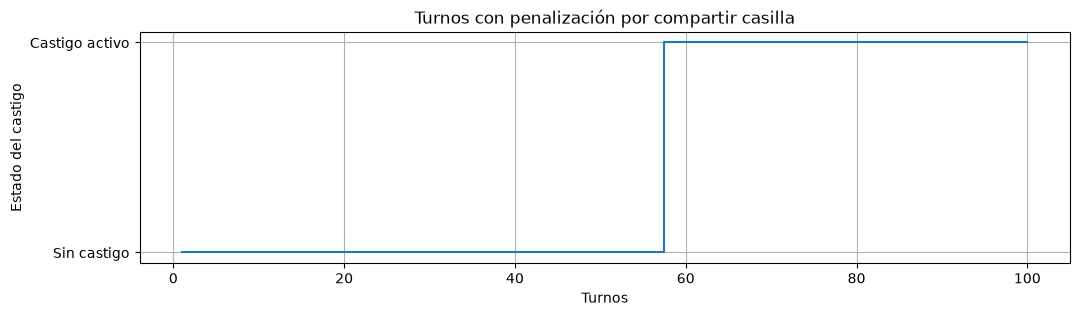

In [24]:

print("RESULTADOS DEL ENTRENAMIENTO")
print("------------------------------------")

print(
    f"Promedio de puntos Agente A: "
    f"{np.mean(puntos_finales_A):.2f}"
)

print(
    f"Promedio de puntos Agente B: "
    f"{np.mean(puntos_finales_B):.2f}"
)

print(
    f"Mejor resultado Agente A: "
    f"{np.max(puntos_finales_A):.2f}"
)

print(
    f"Mejor resultado Agente B: "
    f"{np.max(puntos_finales_B):.2f}"
)


print("\nULTIMA PARTIDA")
print("------------------------------------")

print(
    f"{'Turno':<7}"
    f"{'Posición A':<13}"
    f"{'Posición B':<13}"
    f"{'Acción A':<13}"
    f"{'Acción B':<13}"
    f"{'Recomp. A':<12}"
    f"{'Recomp. B':<12}"
    f"{'Juntos':<8}"
    f"{'Castigo':<8}"
)

for r in historial:

    posicion_A = (r["x_A"], r["y_A"])
    posicion_B = (r["x_B"], r["y_B"])

    print(
        f"{r['turno']:<7}"
        f"{str(posicion_A):<13}"
        f"{str(posicion_B):<13}"
        f"{r['accion_A']:<13}"
        f"{r['accion_B']:<13}"
        f"{r['recompensa_A']:<12.2f}"
        f"{r['recompensa_B']:<12.2f}"
        f"{r['contador_juntos']:<8}"
        f"{str(r['castigo']):<8}"
    )


plt.figure(figsize=(10, 5))

plt.plot(
    puntos_medios_A,
    label="Agente A - Incremental"
)

plt.plot(
    puntos_medios_B,
    label="Agente B - Gradiente"
)

plt.xlabel("Turnos")
plt.ylabel("Puntos acumulados promedio")

plt.title("Puntos acumulados de los agentes")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    recompensas_medias_A,
    label="Agente A - Incremental"
)

plt.plot(
    recompensas_medias_B,
    label="Agente B - Gradiente"
)

plt.xlabel("Turnos")
plt.ylabel("Recompensa promedio")

plt.title("Recompensa obtenida por turno")

plt.legend()
plt.grid(True)
plt.show()


x_A = [inicio_A[0]] + [r["x_A"] for r in historial]
y_A = [inicio_A[1]] + [r["y_A"] for r in historial]

x_B = [inicio_B[0]] + [r["x_B"] for r in historial]
y_B = [inicio_B[1]] + [r["y_B"] for r in historial]


plt.figure(figsize=(8, 8))

plt.imshow(
    mapa_perfiles,
    cmap="YlGn",
    origin="upper",
    alpha=0.4,
    vmin=0,
    vmax=5
)

plt.plot(
    x_A,
    y_A,
    marker="o",
    markersize=3,
    label="Agente A - Incremental"
)

plt.plot(
    x_B,
    y_B,
    marker="o",
    markersize=3,
    label="Agente B - Gradiente"
)

plt.scatter(
    inicio_A[0],
    inicio_A[1],
    marker="s",
    s=120,
    label="Inicio A"
)

plt.scatter(
    inicio_B[0],
    inicio_B[1],
    marker="s",
    s=120,
    label="Inicio B"
)

for y in range(filas):

    for x in range(columnas):

        perfil = mapa_perfiles[y, x]

        if perfil != 0:

            plt.text(
                x,
                y,
                f"P{perfil}",
                ha="center",
                va="center",
                fontsize=11
            )

plt.xticks(range(columnas))
plt.yticks(range(filas))

plt.xlim(-0.5, columnas - 0.5)
plt.ylim(filas - 0.5, -0.5)

plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")

plt.title("Recorrido de los agentes en el tablero 5x5")

plt.grid(True)
plt.legend()
plt.show()


castigos = [
    1 if r["castigo"] else 0
    for r in historial
]

turnos_grafica = [
    r["turno"] for r in historial
]

plt.figure(figsize=(12, 3))

plt.step(
    turnos_grafica,
    castigos,
    where="mid"
)

plt.yticks(
    [0, 1],
    ["Sin castigo", "Castigo activo"]
)

plt.xlabel("Turnos")
plt.ylabel("Estado del castigo")

plt.title("Turnos con penalización por compartir casilla")

plt.grid(True)
plt.show()
